In [1]:
from matplotlib import pyplot as plt
import numpy as np
import torch
import pywt
import sys

from pathlib import Path as _Path
PROJECT_ROOT = str(next(p for p in [_Path.cwd(), *_Path.cwd().parents] if (p / "pyproject.toml").exists()))  # repo root, works on laptop and cluster
sys.path.insert(0, PROJECT_ROOT)

from waveletflux.utils.well_data import get_well_dataset

In [2]:
well_base_path    = f'{PROJECT_ROOT}/data/datasets'
well_dataset_name = 'turbulent_radiative_layer_2D'

dataset = get_well_dataset(
    path=well_base_path,
    physics=well_dataset_name,
    split='test',
    steps=-1,          # loads full trajectory
)

meta_field_names = dataset.metadata.field_names
field_names = [item for sublist in meta_field_names.values() for item in sublist]

In [3]:
item = dataset[5]

# Previous Frames

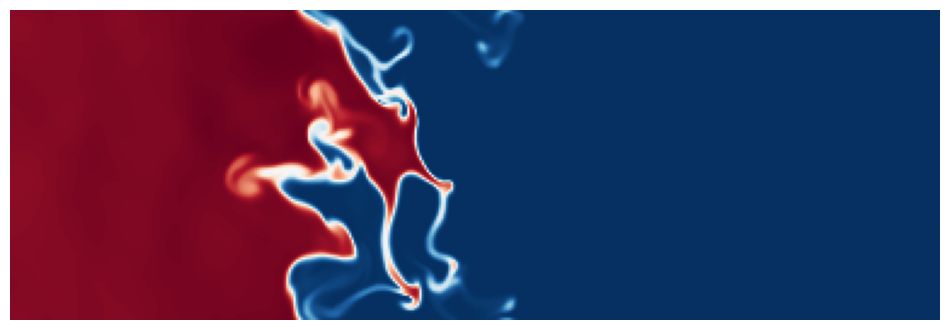

In [12]:
plt.figure(figsize=(12, 6))
plt.imshow(item['input_fields'][66, :, :, 0], cmap='RdBu_r') #.mT.cpu(), origin='lower')
plt.axis('off')
plt.savefig("density_t+1.png", bbox_inches='tight', dpi=150)

In [ ]:
plt.figure(figsize=(12, 6))
plt.imshow(item['input_fields'][64, :, :, 0], cmap='RdBu_r') #.mT.cpu(), origin='lower')

In [ ]:
def multi_scale_wavelet_plot(signal: np.array, 
                        max_levels: int, 
                        level: int = 1,
                        wavelet: pywt = 'haar',
                        mode: str = 'sym', 
                        figsize: tuple = (15, 15),
                        cmap: str = 'RdBu_r',
                        subplot_spec: plt.figure = None, 
                        fig: plt.figure = None,
                        outer_grid: plt.figure = None,
                        wspace: float = 0.01,
                        hspace: float = 0.01,
                        figname: str = None):
    
    if (level > max_levels) or (max_levels < level):
        return
    
    if (fig is None) and (outer_grid is None):
        fig = plt.figure(figsize=figsize if not None else (15, 15))
        outer_grid = fig.add_gridspec(2, 2, wspace=wspace, hspace=hspace)
    
    # If it's the first call, set up the outer grid
    if (subplot_spec is None):
        subplot_spec = outer_grid[0, 0]  # Start with the top-left corner
    
    # Perform one level of 2D DWT
    cA, (cH, cV, cD) = pywt.dwt2(signal, wavelet=wavelet, mode=mode)
    # Arrange approximation and details in a list
    coeffs = [cA, cH, cV, cD]
    # normalize each coefficient array independently for better visibility
    #coeffs = [c/np.abs(c).max() for c in coeffs]
    
    # Set up a 2x2 grid for the current level within the provided subplot_spec
    inner_grid = subplot_spec.subgridspec(2, 2, wspace=wspace*level, hspace=hspace*level)
    
    for i in range(2):
        for j in range(2):
            ax = fig.add_subplot(inner_grid[i, j])
            ax.axis('off')           # Disable axis ticks and labels
            ax.set_frame_on(False)   # Remove the border/frame

            if (i == j == 0) and (level < max_levels):
                # Recursively plot in the top-left cell with the approximation coefficients
                multi_scale_wavelet_plot(coeffs[0], level=level + 1, max_levels=max_levels, subplot_spec=inner_grid[i, j], fig=fig, outer_grid=outer_grid)
            else:
                # Plot detail coefficients (cH, cV, cD) in other cells
                #ax.imshow(coeffs[i * 2 + j], cmap=cmap, vmin=-1, vmax=20)
                ax.imshow(coeffs[i * 2 + j], cmap=cmap, vmin=-1, vmax=100)
                #ax.imshow(coeffs[i * 2 + j], cmap=cmap)


    if figname is not None:
        plt.savefig(figname, bbox_inches='tight', dpi=150, pad_inches=0)

# Noise

In [ ]:
wspace = 0.001
hspace = 0.02

fig = plt.figure(figsize=(9, 3))
grid = fig.add_gridspec(2, 2, wspace=wspace, hspace=hspace)

ax = fig.add_subplot(grid[0, 0])
ax.imshow(torch.randn((64, 192)), cmap='gray', vmin=-1, vmax=1)
plt.axis('off')

ax = fig.add_subplot(grid[0, 1])
ax.imshow(torch.randn((64, 192)), cmap='gray', vmin=-1, vmax=1)
plt.axis('off')

ax = fig.add_subplot(grid[1, 0])
ax.imshow(torch.randn((64, 192)), cmap='gray', vmin=-1, vmax=1)
plt.axis('off')

ax = fig.add_subplot(grid[1, 1])
ax.imshow(torch.randn((64, 192)), cmap='gray', vmin=-1, vmax=1)
plt.axis('off')

plt.savefig('noise_scale_3.png', bbox_inches='tight', dpi=150, pad_inches=0)


## DWT Scale 1

In [ ]:
multi_scale_wavelet_plot(item['input_fields'][66, :, :, 0], 
                         max_levels=1, 
                         wavelet='haar', 
                         mode='periodization', 
                         figsize=(9, 3), 
                         cmap='RdBu_r', 
                         wspace=0.01, 
                         hspace=0.01,
                         figname='multi_scale_wavelet_plot_scale_1_step_66.png')
coeff = pywt.dwt2(item['input_fields'][64, :, :, 0], wavelet='haar', mode='periodization')

## DWT Scale 2

In [ ]:
multi_scale_wavelet_plot(coeff[0], 
                         max_levels=1, 
                         wavelet='haar', 
                         mode='periodization', 
                         figsize=(9, 3), 
                         cmap='RdBu_r', 
                         wspace=0.01, 
                         hspace=0.01,
                         figname='multi_scale_wavelet_plot_scale_2_step_66.png')
coeff = pywt.dwt2(coeff[0], wavelet='haar', mode='periodization')

## Scale 3

In [ ]:
multi_scale_wavelet_plot(coeff[0], 
                         max_levels=1, 
                         wavelet='haar', 
                         mode='periodization', 
                         figsize=(15/3, 5.1/3), 
                         cmap='RdBu_r', 
                         wspace=0.01, 
                         hspace=0.01,
                         figname='multi_scale_wavelet_plot_scale_3_step_66.png')